# 4. Running the circuit: laptop first, then ibm_fez

One notebook, one switch.

- `USE_HARDWARE = False`: FakeFez, the ibm_fez noise model simulated on this laptop. Small patches only.
- `USE_HARDWARE = True`: the real ibm_fez through the saved account `Faryad-free-ibm`.

The data, the circuit, the measurement, and the scoring are the same in both modes.
On hardware nothing is submitted until `SUBMIT = True`. Job ids are written to disk before anything is awaited,
so the notebook can be closed and reopened. A second run with the same settings does not resubmit.

Mitigation is readout only (TREX). No ZNE.

In [1]:
import os, sys
from pathlib import Path
# Find the project folder (the one holding the pqk100 package), wherever Jupyter or VS Code started
def _find_root():
    starts = [Path(p).parent for p in [globals().get("__vsc_ipynb_file__")] if p]
    starts += [Path.cwd(), Path(r"D:\Active Research Projects\PQK100")]
    for s in starts:
        for p in [s, *s.parents]:
            if (p / "pqk100" / "__init__.py").exists() and (p / "credits").is_dir():
                return p.resolve()
    raise RuntimeError(f"Cannot find the PQK100 project folder from {Path.cwd()}. "
                       "Set ROOT = Path(r'D:\\Active Research Projects\\PQK100') by hand in this cell.")
ROOT = _find_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("project folder:", ROOT)

USE_HARDWARE = False        # False: FakeFez on the laptop.   True: ibm_fez
SUBMIT       = False        # hardware only. Read the cost in section 4.5 first, then set True and run again.

ACCOUNT, DEVICE = "Faryad-free-ibm", "ibm_fez"

N_QUBITS  = 156 if USE_HARDWARE else 10      # local simulation with noise is practical up to about 14 qubits
REPS      = 2                                # repetitions of the feature-map block
BANDWIDTH = 0.5                              # radians per standard deviation of expression
FMAP      = "zz"

# TCGA train, TCGA held-out, METABRIC. Pilot sizes on hardware; smaller on the laptop so it runs in a few minutes.
N_TRAIN, N_TEST, N_EXT = (40, 20, 20) if USE_HARDWARE else (24, 12, 12)
SHOTS = 1024 if USE_HARDWARE else 512        # per measurement basis
CHUNK = 20                                   # samples per job
SEED  = 0

TAG = f"TP53_{FMAP}_n{N_QUBITS}_r{REPS}_bw{BANDWIDTH}_s{SEED}_{N_TRAIN}-{N_TEST}-{N_EXT}_{SHOTS}sh_{'fez' if USE_HARDWARE else 'local'}"
print(TAG)

project folder: D:\Active Research Projects\PQK100
TP53_zz_n10_r2_bw0.5_s0_24-12-12_512sh_local


In [2]:
import json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2, QiskitRuntimeService

import pqk100.baselines as B
from pqk100.data import load_cohorts
from pqk100.prep import make_split, select_genes, to_angles
from pqk100.lattice import patch
from pqk100.featuremap import FEATURE_MAPS, to_circuit, cone_stats
from pqk100.lightcone import projections
from pqk100.kernel import features, fit_pqk
from pqk100.hardware import circuit_report, estimate_minutes

class Stop(Exception):
    """Halts 'Run All' with a one-line message instead of a traceback."""
    def _render_traceback_(self):
        return [f"STOPPED: {self}"]

JOBS = Path("results/jobs"); JOBS.mkdir(parents=True, exist_ok=True)

## 4.1 Data to rotation angles

The genes are chosen on the training tumors only. Each row of `angles` is one tumor; column q is the angle on qubit q.

In [3]:
tcga, meta = load_cohorts()
sp = make_split(tcga, meta, "TP53", N_TRAIN, N_TEST, N_EXT, SEED, scaling="cohort")
genes = select_genes(sp.Xtr, sp.ytr, N_QUBITS)
Z = np.vstack([sp.Xtr[:, genes], sp.Xte[:, genes], sp.Xex[:, genes]])
ntr, nte = len(sp.ytr), len(sp.yte)
angles = to_angles(Z, BANDWIDTH)
print(f"{len(angles)} samples ({ntr} train, {nte} held-out TCGA, {len(sp.yex)} METABRIC), {angles.shape[1]} angles each")
print("panel starts with:", ", ".join(sp.genes[genes[:8]]))

48 samples (24 train, 12 held-out TCGA, 12 METABRIC), 10 angles each
panel starts with: SIM2, CHRNA5, ACSM3, CSMD2, PTPRU, GGT1, TMEM101, PLEKHG4


## 4.2 Backend

In [4]:
if USE_HARDWARE:
    service = QiskitRuntimeService(name=ACCOUNT)
    backend = service.backend(DEVICE)
    st = backend.status()
    print(f"{backend.name}: {backend.num_qubits} qubits, operational={st.operational}, pending jobs={st.pending_jobs}")
    try:
        print("account usage:", service.usage())
    except Exception as e:
        print("usage not available from this client:", type(e).__name__)
else:
    from qiskit_ibm_runtime.fake_provider import FakeFez
    service, backend = None, FakeFez()
    print(f"{backend.name}: {backend.num_qubits} qubits (local noise model)")

fake_fez: 156 qubits (local noise model)


## 4.3 Patch

A connected patch of `N_QUBITS` qubits, chosen from the calibration data of the backend above.
On hardware this uses today's calibration, so the patch can differ from run to run. It is saved with the job ids.

In [5]:
phys, edges = patch(backend, N_QUBITS)
t = backend.target
inside = set(phys)
ro = np.array([t["measure"][(q,)].error for q in phys if t["measure"].get((q,)) is not None and t["measure"][(q,)].error is not None])
cz = np.array([p.error for qs, p in t["cz"].items() if qs[0] in inside and qs[1] in inside and p is not None and p.error is not None])
print(f"patch: {len(phys)} qubits, {len(edges)} couplers")
print(f"readout error: median {np.median(ro):.4f}, worst {ro.max():.4f}")
print(f"CZ error:      median {np.median(cz):.4f}, worst {cz.max():.4f}")

patch: 10 qubits, 9 couplers
readout error: median 0.0090, worst 0.0459
CZ error:      median 0.0042, worst 0.0075


## 4.4 Circuit

The feature map is built once with one parameter per gene, and transpiled once onto the patch.
Every tumor is then a row of parameter values. The patch couplers are native, so no SWAP gates are needed.

In [6]:
ops = FEATURE_MAPS[FMAP](N_QUBITS, edges, reps=REPS)
qc, x = to_circuit(N_QUBITS, ops)

pm = generate_preset_pass_manager(optimization_level=1, backend=backend, initial_layout=list(phys), seed_transpiler=0)
isa = pm.run(qc)
assert list(isa.layout.final_index_layout()) == list(phys), "routing moved qubits"

rep = circuit_report(isa, backend)
print(f"logical circuit : {qc.num_qubits} qubits, {sum(o.gate in ('rzz', 'cz') for o in ops)} two-qubit gates")
print(f"on the device   : {rep['twoq_gates']} CZ gates, CZ depth {rep['twoq_depth']}, {rep['circuit_s']*1e6:.1f} us long")
print(f"gates used      : {dict(isa.count_ops())}")

logical circuit : 10 qubits, 18 two-qubit gates
on the device   : 36 CZ gates, CZ depth 8, 1.0 us long
gates used      : {'rz': 190, 'sx': 76, 'cz': 36}


In [7]:
# X, Y, Z on every qubit of the patch: 3 * N observables, shape (3N, 1) so they broadcast over the samples.
observables = [[SparsePauliOp.from_sparse_list([(P, [k], 1.0)], num_qubits=N_QUBITS).apply_layout(isa.layout)]
               for P in "XYZ" for k in range(N_QUBITS)]
param_cols = [p.index for p in isa.parameters]      # column of `angles` for each circuit parameter
values = angles[:, param_cols]
print(len(observables), "observables,", values.shape, "parameter values")

30 observables, (48, 10) parameter values


## 4.5 Exact values and cost

The exact expectation values come from the light-cone simulator (notebook 2). They are the reference for the device.

In [8]:
size, n2q, ncz = cone_stats(N_QUBITS, ops)
exact = projections(N_QUBITS, ops, angles)[0] if size.max() <= 24 else None
print(f"largest light cone: {size.max()} qubits, up to {ncz.max()} CZ gates in a cone")

n_circuits = len(angles) * 3
minutes = estimate_minutes(rep, len(angles), SHOTS)
print(f"\n{len(angles)} samples x 3 bases x {SHOTS} shots = {n_circuits * SHOTS:,} shots")
print(f"one shot: {rep['shot_s']*1e6:.0f} us (repetition delay {rep['rep_delay_s']*1e6:.0f} us)")
print(f"estimated QPU time: {minutes:.1f} min  (includes a 1.5x allowance for overhead; the Open Plan gives 10 min per 28 days)")

largest light cone: 5 qubits, up to 12 CZ gates in a cone

48 samples x 3 bases x 512 shots = 73,728 shots
one shot: 253 us (repetition delay 250 us)
estimated QPU time: 0.5 min  (includes a 1.5x allowance for overhead; the Open Plan gives 10 min per 28 days)


## 4.6 Estimator and submission

`resilience_level = 1` is TREX readout mitigation. ZNE and gate twirling stay off.
In local mode these options are not used; the fake backend returns raw noisy values.

In [9]:
estimator = EstimatorV2(mode=backend)
estimator.options.default_shots = SHOTS
if USE_HARDWARE:
    estimator.options.resilience_level = 1
    estimator.options.resilience.measure_mitigation = True
    estimator.options.resilience.zne_mitigation = False
    estimator.options.twirling.enable_measure = True
    estimator.options.twirling.enable_gates = False
    estimator.options.dynamical_decoupling.enable = False

job_file = JOBS / f"{TAG}.json"
if USE_HARDWARE and job_file.exists():
    record = json.loads(job_file.read_text())
    print(f"Already submitted on {record['created']}: {len(record['jobs'])} jobs. Not submitting again.")
    jobs = [service.job(j["id"]) for j in record["jobs"]]
elif USE_HARDWARE and not SUBMIT:
    raise Stop(f"nothing submitted. Estimated cost {minutes:.1f} min. Set SUBMIT = True in the first cell and run again.")
else:
    record = {"tag": TAG, "backend": backend.name, "created": time.strftime("%Y-%m-%d %H:%M:%S"), "shots": SHOTS,
              "phys": [int(q) for q in phys], "genes": [str(g) for g in sp.genes[genes]], "jobs": []}
    jobs = []
    for s in range(0, len(values), CHUNK):
        job = estimator.run([(isa, observables, values[s:s + CHUNK])])
        jobs.append(job)
        record["jobs"].append({"id": job.job_id(), "start": s, "stop": min(s + CHUNK, len(values))})
        if USE_HARDWARE:
            job_file.write_text(json.dumps(record, indent=1))        # saved after every submission
    np.save(JOBS / f"{TAG}_angles.npy", angles)
    print(f"submitted {len(jobs)} jobs" + (f"; ids in {job_file}" if USE_HARDWARE else " to the local simulator"))

submitted 3 jobs to the local simulator


## 4.7 Collect

On hardware, run this cell again later if the jobs are still queued. Nothing is resubmitted.

In [10]:
if USE_HARDWARE:
    states = [str(j.status()) for j in jobs]
    print(pd.Series(states).value_counts().to_string())
    if any(s in ("ERROR", "CANCELLED") for s in states):
        raise Stop("a job failed or was cancelled. Inspect it on the IBM Quantum dashboard; delete " + str(job_file) + " to start over.")
    if any(s != "DONE" for s in states):
        raise Stop("jobs are not finished yet. Run this cell again later.")

P_dev, P_err = [], []
for job in jobs:
    data = job.result()[0].data
    P_dev.append(np.asarray(data.evs).reshape(3, N_QUBITS, -1).transpose(2, 0, 1))     # (samples, 3, qubits)
    P_err.append(np.asarray(data.stds).reshape(3, N_QUBITS, -1).transpose(2, 0, 1))
P_dev, P_err = np.concatenate(P_dev), np.concatenate(P_err)
np.save(JOBS / f"{TAG}_projections.npy", P_dev)
print("projections:", P_dev.shape, " median standard error:", round(float(np.median(P_err)), 4))

if USE_HARDWARE:
    try:
        used = sum(float(j.usage()) for j in jobs)
        print(f"QPU time billed: {used:.0f} s = {used/60:.2f} min  (estimate was {minutes:.1f} min)")
        print(f"effective time per shot: {used / (len(angles) * 3 * SHOTS) * 1e6:.0f} us")
    except Exception as e:
        print("usage not reported:", type(e).__name__)

projections: (48, 3, 10)  median standard error: 0.042


## 4.8 Device against exact

For each qubit, the slope of measured against exact values is the fraction of signal that survived.
The crude expectation is (1 - CZ error) raised to the number of CZ gates in that qubit's light cone.

correlation with exact values: 0.9951
signal retained per qubit: median 0.945, worst 0.889, best 0.976
gate-error-only expectation: median 0.951
weakest qubits (physical index: retained): 41: 0.89, 43: 0.91, 42: 0.92, 21: 0.94, 3: 0.94


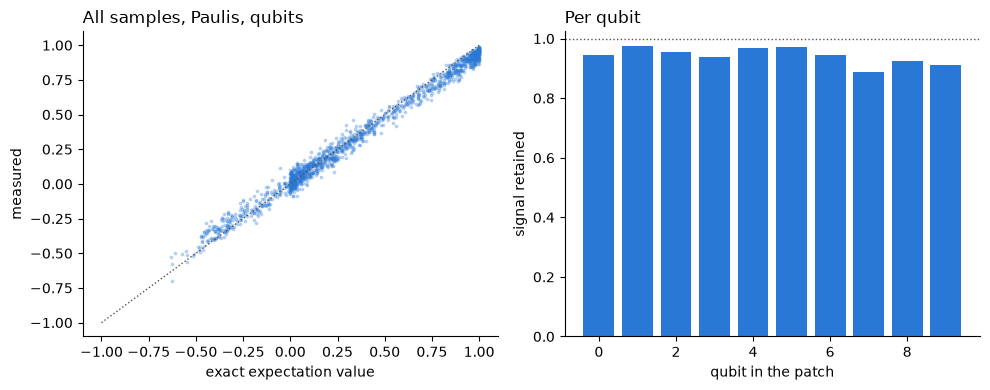

In [11]:
if exact is None:
    print("Light cones too large for the exact reference at this depth. Use the MPS check from notebook 2.")
else:
    r = np.corrcoef(P_dev.ravel(), exact.ravel())[0, 1]
    keep = (P_dev * exact).sum((0, 1)) / (exact ** 2).sum((0, 1))          # per qubit
    eps = float(np.median(cz))
    print(f"correlation with exact values: {r:.4f}")
    print(f"signal retained per qubit: median {np.median(keep):.3f}, worst {keep.min():.3f}, best {keep.max():.3f}")
    print(f"gate-error-only expectation: median {np.median((1 - eps) ** ncz):.3f}")

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot([-1, 1], [-1, 1], color="#52514e", lw=1, ls=":")
    ax[0].scatter(exact.ravel(), P_dev.ravel(), s=3, alpha=0.25, color="#2a78d6", rasterized=True)
    ax[0].set_xlabel("exact expectation value"); ax[0].set_ylabel("measured"); ax[0].set_title("All samples, Paulis, qubits", loc="left")
    ax[1].bar(np.arange(N_QUBITS), keep, color="#2a78d6", width=0.8)
    ax[1].axhline(1.0, color="#52514e", lw=1, ls=":")
    ax[1].set_xlabel("qubit in the patch"); ax[1].set_ylabel("signal retained"); ax[1].set_title("Per qubit", loc="left")
    for a in ax:
        a.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    worst = np.argsort(keep)[:5]
    print("weakest qubits (physical index: retained):", ", ".join(f"{phys[k]}: {keep[k]:.2f}" for k in worst))

## 4.9 Classification

The same SVM tuning for device features, exact features, and the classical models.
With the pilot sizes (a few dozen training tumors) these numbers only show that the pipeline runs end to end.
The sizes for a real comparison are in the last section.

In [12]:
split = lambda M: {"in": (M[ntr:ntr + nte], sp.yte), "ext": (M[ntr + nte:], sp.yex)}
res = {}
Fd = features(P_dev);  res["PQK (device)" if USE_HARDWARE else "PQK (local noise model)"] = B.evaluate(fit_pqk, Fd[:ntr], sp.ytr, split(Fd), SEED)
if exact is not None:
    Fe = features(exact); res["PQK (exact)"] = B.evaluate(fit_pqk, Fe[:ntr], sp.ytr, split(Fe), SEED)
res["RBF-SVM"] = B.evaluate(B.fit_rbf_svm, Z[:ntr], sp.ytr, split(Z), SEED)
res["Logistic regression"] = B.evaluate(B.fit_logreg, Z[:ntr], sp.ytr, split(Z), SEED)
scores = pd.DataFrame({k: {"CV AUC (train)": r["cv_auc"], "AUC held-out TCGA": r["in_auc"], "AUC METABRIC": r["ext_auc"]}
                       for k, r in res.items()}).T.round(3)
scores.to_csv(JOBS / f"{TAG}_scores.csv")
scores

,CV AUC (train),AUC held-out TCGA,AUC METABRIC
PQK (local noise model),1.0,0.875,0.688
PQK (exact),1.0,0.844,0.719
RBF-SVM,1.0,0.875,0.781
Logistic regression,1.0,0.844,0.781


## 4.10 Settings for the real runs

Cost depends on samples and shots, not on qubit count or depth, because the repetition delay dominates each shot.

| Purpose | Qubits | Reps | Train / held-out / METABRIC | Shots | Estimated QPU time |
|---|---|---|---|---|---|
| Pilot: true cost and signal retained | 156 | 2 | 40 / 20 / 20 | 1,024 | about 2 min |
| One point of the scaling study | 20 to 156 | 1 to 3 | 200 / 200 / 200 | 1,024 | about 12 min each |

The pilot fits in the Open Plan's 10 minutes. The scaling study needs the one-time 180-minute allocation.
Replace the estimates with the billed time printed in section 4.7 once the pilot has run.